# Guía L2 — El índice sancocho · **Sesión 2: el índice en el tiempo y el duelo de ciudades**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

Hoy la olla se pone histórica: años de precios oficiales, los picos con nombre propio, el duelo de ciudades, la apuesta de conmutatividad y la unidad monetaria más seria jamás inventada: **el sancocho**.

**Antes de ejecutar:** predicciones P4 y P5 de la guía, en papel, foto al informe. P5 es la apuesta central del laboratorio — no se la salten, que sin apuesta no hay gloria.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/sipsa_mensual.csv.gz"
df = pd.read_csv(RUTA)

# La receta oficial y el pipeline de la sesión 1 (los reconstruimos aquí para
# que este cuaderno sea autónomo — reproducibilidad ante todo):
RECETA = {
    "Carne de cerdo, espinazo":       1.5,
    "Yuca ICA":                       1.0,
    "Papa capira":                    1.0,
    "Chócolo mazorca":                0.9,
    "Plátano dominico hartón verde":  1.4,
}

def indice_plato(tabla, ciudad, receta):
    "tabla -> serie: costo del plato mes a mes en una ciudad. El pipeline entero, empacado."
    # Si hay varias centrales en la ciudad, se usa su promedio simple por producto y mes.
    t = tabla[(tabla["ciudad"] == ciudad) & (tabla["producto"].isin(receta))]
    p = t.pivot_table(index="fecha", columns="producto", values="precio_kg", aggfunc="mean")
    faltantes = [producto for producto in receta if producto not in p.columns]
    if faltantes:
        raise ValueError(f"{ciudad}: faltan ingredientes de la receta: {faltantes}")
    p = p[list(receta)]
    meses_incompletos = p.index[p.isna().any(axis=1)].to_list()
    if meses_incompletos:
        raise ValueError(f"{ciudad}: receta incompleta en {len(meses_incompletos)} meses; primero revisen la sustitución.")
    return p.mul(pd.Series(receta), axis="columns").sum(axis=1)

print("Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta.",
      "Nada global. Cambiar de plato será cambiar un diccionario.")

Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta. Nada global. Cambiar de plato será cambiar un diccionario.


---
## 1 · El índice sancocho, 2013 en adelante

Confronten con su P4: ¿la curva que bosquejaron se parece a la real?

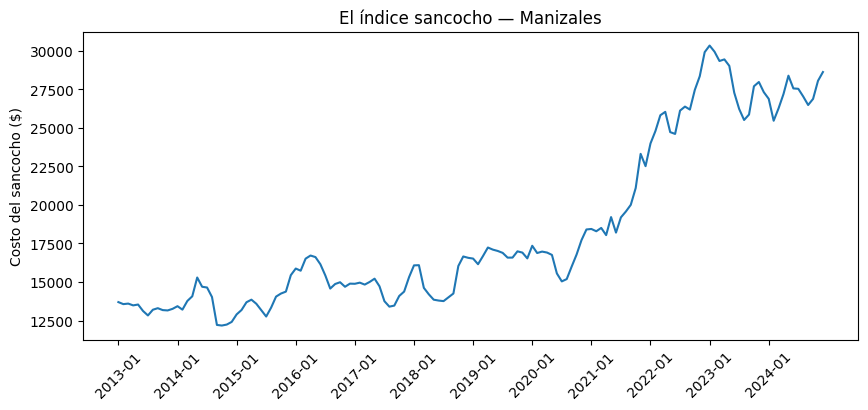

Primer mes (2013-01): $13,695
Último mes (2024-12): $28,634
Variación total: 109.1%


In [ ]:
sancocho_mzl = indice_plato(df, "Manizales", RECETA)

plt.figure(figsize=(10, 4))
plt.plot(range(len(sancocho_mzl)), sancocho_mzl.values)
paso = 12
plt.xticks(range(0, len(sancocho_mzl), paso), sancocho_mzl.index[::paso], rotation=45)
plt.ylabel("Costo del sancocho ($)")
plt.title("El índice sancocho — Manizales")
plt.show()

print(f"Primer mes ({sancocho_mzl.index[0]}): ${sancocho_mzl.iloc[0]:,.0f}")
print(f"Último mes ({sancocho_mzl.index[-1]}): ${sancocho_mzl.iloc[-1]:,.0f}")
print(f"Variación total: {100*(sancocho_mzl.iloc[-1]/sancocho_mzl.iloc[0]-1):.1f}%")

In [ ]:
# Saltos más bruscos: cuánto cambió el costo de un mes al siguiente (en %)
cambio = sancocho_mzl.pct_change() * 100
print("Las 5 subidas más grandes de un mes a otro:")
print(cambio.sort_values(ascending=False).head(5).round(1))

Las 5 subidas más grandes de un mes a otro:
fecha
2018-10    12.5
2021-11    10.5
2014-05     8.7
2015-12     7.4
2023-10     7.1
dtype: float64


In [ ]:
# ¿Qué ingrediente empujó cada salto? Cambio en pesos de cada ingrediente respecto al mes anterior
precios = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA))]
precios = precios.pivot_table(index="fecha", columns="producto", values="precio_kg", aggfunc="mean")
aporte = precios[list(RECETA)].mul(pd.Series(RECETA), axis="columns")   # pesos que pone cada ingrediente

for mes in ["2018-10", "2021-11"]:
    i = aporte.index.get_loc(mes)
    print(f"\n{mes}: cuánto subió cada ingrediente en pesos")
    print((aporte.iloc[i] - aporte.iloc[i - 1]).round(0).sort_values(ascending=False))


2018-10: cuánto subió cada ingrediente en pesos
producto
Carne de cerdo, espinazo         1125.0
Plátano dominico hartón verde     315.0
Papa capira                       185.0
Yuca ICA                          156.0
Chócolo mazorca                     5.0
dtype: float64

2021-11: cuánto subió cada ingrediente en pesos
producto
Carne de cerdo, espinazo         1500.0
Yuca ICA                          362.0
Papa capira                       257.0
Chócolo mazorca                   126.0
Plátano dominico hartón verde     -27.0
dtype: float64


🗣️ **Los picos tienen nombre.** Elijan los **dos** saltos más bruscos de la curva. Para cada uno: ¿en qué mes ocurre?, ¿qué pasó en Colombia por esas fechas? (Pistas de historiador: paros, fenómenos de El Niño o La Niña, cosechas, tasa de cambio. Busquen — con IA si quieren, documentando — y sustenten: hipótesis + evidencia, tres líneas por pico.)

Pico 1, octubre de 2018 (+12,5 %): El salto lo empujó la carne: el espinazo explica unos \$1.125 de los ~\$1.786 que subió el plato (63 %). Fuentes del gremio y del DANE confirman que el cerdo subió esas semanas: Porkcolombia reporta alzas de 2 a 3 % en el precio del cerdo en pie y el boletín SIPSA del DANE pone el espinazo entre los productos que más subieron en Cúcuta, así que fue un alza del cerdo en varias ciudades y no solo en Manizales. Nuestra hipótesis es un menor abastecimiento de cerdo, pero no encontramos una fuente que lo confirme. Fuentes: Porkcolombia, semana 42 de 2018; Boletín SIPSA-DANE, 27 oct–2 nov 2018.

Pico 2, noviembre de 2021 (+10,5 %): Otra vez la carne: el espinazo explica unos \$1.500 de los ~\$2.218 (68 %). Creemos que subió por dos razones: los efectos del paro nacional de 2021 sobre los precios de los alimentos y el aumento del concentrado con que se alimentan los cerdos, que se hace con maíz y soya; Colombia importa casi la mitad del maíz y el dólar estaba alto. En 2021 la carne de cerdo subió 23,5 %. Fuentes: Bloomberg Línea, enero 2022; La República, marzo 2022.

---
## 2 · El duelo de ciudades (y el problema de la sustitución)

El sancocho "igual" no existe entre ciudades: el conjunto oficial obliga a decidir **equivalencias** de variedades y cortes. Además, cuando hay varias centrales en una ciudad, `indice_plato` usa el promedio simple de sus observaciones disponibles por producto y mes. El cuaderno trae una receta base que funciona los 144 meses; no es una verdad culinaria. Ambas son decisiones de modelación: defiéndanlas.

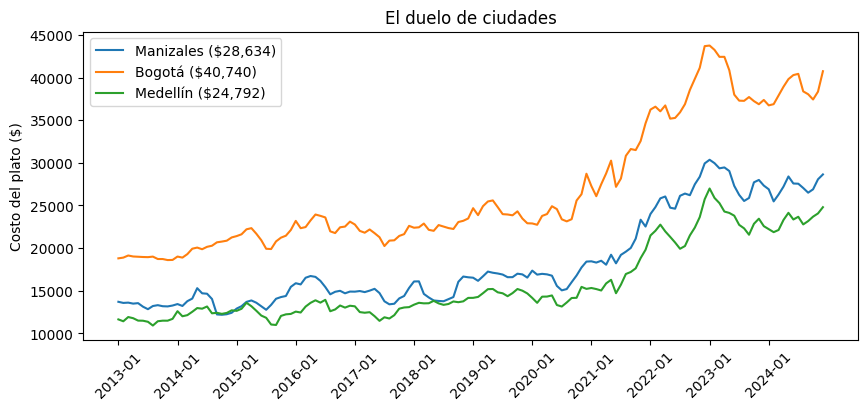

,inicio,final,aumento en pesos,aumento porcentual
Manizales,13695.0,28634.0,14939.0,109.1
Bogotá,18791.0,40740.0,21949.0,116.8
Medellín,11631.0,24792.0,13161.0,113.2


In [ ]:
# ✏️ Ejercicio 1 — Revisen las equivalencias y, si las cambian, defiendan la decisión.
# Pista: df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()

RECETA_BOGOTA = {
    "Carne de cerdo, costilla":    1.5,   # sustitución del espinazo
    "Yuca llanera":               1.0,
    "Papa parda pastusa":         1.0,
    "Chócolo mazorca":            0.9,
    "Plátano hartón verde":       1.4,
}

RECETA_MEDELLIN = {
    "Carne de cerdo, espinazo":  1.5,
    "Yuca criolla":              1.0,   # sustitución de Yuca ICA
    "Papa capira":               1.0,
    "Chócolo mazorca":           0.9,
    "Plátano hartón verde":      1.4,   # sustitución del dominico hartón
}

series = {
    "Manizales": sancocho_mzl,
    "Bogotá":    indice_plato(df, "Bogotá", RECETA_BOGOTA),
    "Medellín":  indice_plato(df, "Medellín", RECETA_MEDELLIN),
}

plt.figure(figsize=(10, 4))
for ciudad, s in series.items():
    plt.plot(range(len(s)), s.values, label=f"{ciudad} (${s.iloc[-1]:,.0f})")
plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
plt.ylabel("Costo del plato ($)")
plt.title("El duelo de ciudades")
plt.legend()
plt.show()

comparacion = pd.DataFrame({
    ciudad: {"inicio": serie.iloc[0], "final": serie.iloc[-1]}
    for ciudad, serie in series.items()
}).T
comparacion["aumento en pesos"] = comparacion["final"] - comparacion["inicio"]
comparacion["aumento porcentual"] = 100 * (comparacion["final"] / comparacion["inicio"] - 1)
comparacion.round({"inicio": 0, "final": 0, "aumento en pesos": 0, "aumento porcentual": 1})

🗣️ **Tabla de equivalencias (escriban aquí):** Manizales: espinazo / Yuca ICA / papa capira / dominico hartón; Bogotá: costilla / yuca llanera / parda pastusa / hartón; Medellín: espinazo / yuca criolla / capira / hartón. Defiendan en tres líneas por qué estas sustituciones permiten comparar platos sin fingir que son idénticos.

¿Dónde es más caro el almuerzo y por cuánto? ¿Las curvas suben al mismo ritmo? Y la pregunta con trampa: **"¿dónde subió más?" tiene dos respuestas legítimas** — en pesos y en porcentaje. Calculen ambas y decidan cuál reportarían, defendiendo la elección.

**Tabla de equivalencias**

| Ingrediente | Manizales | Bogotá | Medellín |
|---|---|---|---|
| Carne | Espinazo de cerdo | Costilla de cerdo | Espinazo de cerdo |
| Yuca | Yuca ICA | Yuca llanera | Yuca criolla |
| Papa | Papa capira | Papa parda pastusa | Papa capira |
| Mazorca | Chócolo mazorca | Chócolo mazorca | Chócolo mazorca |
| Plátano | Plátano dominico hartón verde | Plátano hartón verde | Plátano hartón verde |

**Defensa:** La costilla y el espinazo son carne de cerdo con hueso y cumplen la misma función en el caldo. Las yucas, papas y plátanos son el mismo ingrediente en distinta variedad, la que se vende en cada central. Usamos estas equivalencias porque si un producto no aparece todos los meses en una ciudad, no se puede calcular el índice de los 144 meses; no son platos idénticos, pero sí comparables.

**¿Dónde es más caro?** En Bogotá: \$40.740, contra \$28.634 en Manizales (unos \$12.100 más) y \$24.792 en Medellín, la más barata.

**¿Suben al mismo ritmo?** Casi: las tres curvas tienen la misma forma, con la subida fuerte en 2021–2022, y las tres más que se duplicaron (entre 109 % y 117 %).

**¿Dónde subió más?** Bogotá, en pesos (+\$21.949) y en porcentaje (+116,8 %). Pero Manizales y Medellín cambian de puesto: en pesos subió más Manizales y en porcentaje Medellín. Reportamos en **pesos** porque es lo que una familia siente en el bolsillo.  

---
## 3 · La apuesta central: ¿conmutan?

P5 sobre la mesa. Dos caminos para el "costo típico anual" del sancocho:

- **Camino A:** promediar los 12 precios del año de cada ingrediente → costear la receta una vez.
- **Camino B:** costear la receta mes a mes → promediar los 12 costos.

¿Dan lo mismo? Primero su apuesta escrita, luego el juez:

In [ ]:
AÑO = "2016"
mzl = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]

# Camino A: promediar precios, luego costear
precios_promedio = anual.groupby("producto")["precio_kg"].mean()
camino_A = sum(RECETA[p] * precios_promedio[p] for p in RECETA)

# Camino B: costear cada mes, luego promediar
camino_B = indice_plato(df, "Manizales", RECETA)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].mean()

print(f"Camino A (promediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → promediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")

Camino A (promediar → costear): $15,587.53
Camino B (costear → promediar): $15,587.53
Diferencia: $0.000000


In [ ]:
# ✏️ Ejercicio 2 — Rompan la magia.
import numpy as np

costos_mes = indice_plato(df, "Manizales", RECETA)
costos_año = costos_mes[costos_mes.index.str.startswith(AÑO)]

# --- Con la MEDIANA ---
precios_mediana = anual.groupby("producto")["precio_kg"].median()
camino_A_mediana = sum(RECETA[p] * precios_mediana[p] for p in RECETA)   # mediana de precios → costear
camino_B_mediana = costos_año.median()                                     # costear → mediana de costos
print(f"Mediana · Camino A: ${camino_A_mediana:,.2f}")
print(f"Mediana · Camino B: ${camino_B_mediana:,.2f}")
print(f"Mediana · Diferencia: ${abs(camino_A_mediana - camino_B_mediana):,.2f}\n")

# --- Quitando el 5 % de precios más caros antes de promediar ---
def promedio_sin_5_mas_caro(valores):
    "Promedio después de quitar los valores por encima del percentil 95."
    corte = np.percentile(valores, 95)
    return valores[valores <= corte].mean()

precios_recortados = anual.groupby("producto")["precio_kg"].apply(promedio_sin_5_mas_caro)
camino_A_recorte = sum(RECETA[p] * precios_recortados[p] for p in RECETA)
camino_B_recorte = promedio_sin_5_mas_caro(costos_año)
print(f"Sin 5 % más caro · Camino A: ${camino_A_recorte:,.2f}")
print(f"Sin 5 % más caro · Camino B: ${camino_B_recorte:,.2f}")
print(f"Sin 5 % más caro · Diferencia: ${abs(camino_A_recorte - camino_B_recorte):,.2f}")

# 🗣️ Moraleja: los dos caminos coinciden con el promedio porque la receta es LINEAL
# (costo = Σ kilos·precio, una combinación lineal con pesos fijos) y el promedio también
# lo es: promedio(a·x + b·y) = a·promedio(x) + b·promedio(y). Dos operaciones lineales conmutan,
# y la diferencia del camino A contra el B es solo error de redondeo de punto flotante (~1e-12).
# Con la mediana se rompe porque la mediana NO es lineal: depende del ORDEN de los datos y
# no de su suma, así que mediana(x + y) ≠ mediana(x) + mediana(y). El mes de precio
# mediano de la papa no tiene por qué ser el mes mediano del espinazo ni el del costo total.
# Quitar el 5 % más caro tampoco es lineal: qué dato se quita depende de cuál es el mayor,
# y el mes más caro de cada ingrediente no coincide con el mes más caro del plato.

Mediana · Camino A: $15,643.55
Mediana · Camino B: $15,580.50
Mediana · Diferencia: $63.05

Sin 5 % más caro · Camino A: $15,451.83
Sin 5 % más caro · Camino B: $15,484.67
Sin 5 % más caro · Diferencia: $32.84


---
## 4 · El camino de regreso: la unidad sancocho

Del costo total del plato no se puede recuperar el precio del plátano — la suma colapsa infinitas combinaciones en un número (no inyectiva: información que muere). Pero hay una conversión que sí tiene camino de regreso perfecto:

In [ ]:
VALOR_SANCOCHO = float(sancocho_mzl.iloc[-1])   # 1 sancocho = costo del último mes del congelado

def a_sancochos(pesos):
    return pesos / VALOR_SANCOCHO

def a_pesos(sancochos):
    return sancochos * VALOR_SANCOCHO

# La prueba de fuego de una inversa: ida y vuelta = quedarse quieto.
print("¿a_pesos(a_sancochos(x)) == x?  →", a_pesos(a_sancochos(123456.0)))

# ✏️ Ejercicio 3 — Conviertan a sancochos: el salario mínimo de ese año, la matrícula,
# y la mesada (o el presupuesto mensual de comida) de alguien del equipo que quiera confesarla.
SALARIO_MINIMO = 0        # ← búsquenlo (¡documenten la fuente!)
# print(f"El salario mínimo equivale a {a_sancochos(SALARIO_MINIMO):.1f} sancochos")

# 🗣️ ¿Y la pregunta incómoda: el salario mínimo de 2013 alcanzaba para más o menos
# sancochos que el del último año del dataset? Calcúlenlo. Eso — poder adquisitivo
# medido en almuerzos — es economía seria con matemáticas de primer semestre.

¿a_pesos(a_sancochos(x)) == x?  → 123456.00000000001


In [ ]:
# ✏️ Ejercicio 3 — Conversiones a sancochos
# Fuentes: SMMLV 2024 = $1.300.000 (Decreto 2292 de 2023); SMMLV 2013 = $589.500 (Decreto 2738 de 2012)
SALARIO_MINIMO = 1_300_000      # último año del dataset (2024)
SALARIO_2013   =   589_500
MATRICULA      = 2_000_000      # valor total de la matrícula, sin descuentos
PAGO_REAL      =   300_697      # lo que realmente pago (primer recibo)
GASTO_MES      = 1_100_000      # gasto mensual estimado de un integrante en un mes alto (no es una mesada fija)

print(f"1 sancocho (Manizales, {sancocho_mzl.index[-1]}) = ${VALOR_SANCOCHO:,.0f}\n")
print(f"Salario mínimo 2024           = {a_sancochos(SALARIO_MINIMO):.1f} sancochos")
print(f"Matrícula completa            = {a_sancochos(MATRICULA):.1f} sancochos")
print(f"Lo que pago de matrícula      = {a_sancochos(PAGO_REAL):.1f} sancochos")
print(f"Gasto de un mes alto          = {a_sancochos(GASTO_MES):.1f} sancochos")

# 🗣️ La pregunta incómoda: cada salario se mide con el sancocho de SU año (promedio de los 12 meses)
sancocho_2013 = sancocho_mzl[sancocho_mzl.index.str.startswith("2013")].mean()
sancocho_2024 = sancocho_mzl[sancocho_mzl.index.str.startswith("2024")].mean()
print(f"\nSancocho promedio 2013: ${sancocho_2013:,.0f}  |  2024: ${sancocho_2024:,.0f}")
print(f"Salario mínimo 2013 → {SALARIO_2013 / sancocho_2013:.1f} sancochos")
print(f"Salario mínimo 2024 → {SALARIO_MINIMO / sancocho_2024:.1f} sancochos")

1 sancocho (Manizales, 2024-12) = $28,634

Salario mínimo 2024           = 45.4 sancochos
Matrícula completa            = 69.8 sancochos
Lo que pago de matrícula      = 10.5 sancochos
Gasto de un mes alto          = 38.4 sancochos

Sancocho promedio 2013: $13,325  |  2024: $27,207
Salario mínimo 2013 → 44.2 sancochos
Salario mínimo 2024 → 47.8 sancochos


🗣️ **Conversiones a sancochos** (1 sancocho = \$28.634, Manizales, diciembre de 2024)

- **Salario mínimo 2024** (\$1.300.000) = **45,4 sancochos**.
- **Matrícula completa** (\$2.000.000, sin descuentos) = **69,8 sancochos**; lo que realmente pago con el descuento (\$300.697) = **10,5 sancochos**. El descuento equivale a unos 59 sancochos por semestre.
- **Gasto de un mes alto** de un integrante (\$1.100.000, estimado; no es una mesada fija) = **38,4 sancochos**.

**La pregunta incómoda:** en 2013 el salario mínimo (\$589.500) alcanzaba para **44,2 sancochos** (a precio promedio de 2013) y en 2024 (\$1.300.000) alcanza para **47,8 sancochos** (a precio promedio de 2024). El poder adquisitivo medido en sancochos subió cerca de un 8 %: el salario creció +121 % y el sancocho +104 %. Cada salario se midió con el costo del sancocho de su propio año; usar el mismo valor para los dos años habría mezclado precios de épocas distintas.

*Fuentes: salario mínimo 2013 = Decreto 2738 de 2012; salario mínimo 2024 = Decreto 2292 de 2023.*

---
## 5 · El plato propio (proyecto del equipo)

Cambiar de plato es cambiar un diccionario — esa es la recompensa de haber escrito el pipeline como funciones. Elijan SU plato (ajiaco, mondongo, frijolada, o la receta de su casa con las cantidades que les dicte quien cocina) y construyan su índice.

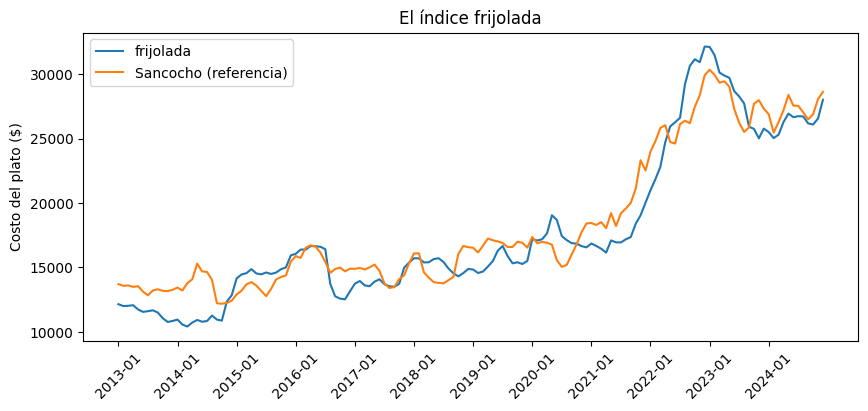

frijolada: $12,140 → $28,015 (+130.8%)
sancocho: $13,695 → $28,634 (+109.1%)
       frijolada  sancocho  brecha
fecha                             
2013        95.3      97.3    -2.0
2014        91.5      98.7    -7.2
2015       121.1     100.1    21.0
2016       123.4     113.8     9.6
2017       115.0     105.9     9.1
2018       125.0     109.5    15.5
2019       126.9     122.4     4.5
2020       143.0     121.4    21.6
2021       143.5     143.9    -0.4
2022       222.0     191.4    30.6
2023       233.8     204.5    29.3
2024       217.0     198.7    18.3


In [ ]:
# ✏️ Ejercicio 4 — Su plato, su índice.
# PROPUESTA: frijolada para seis (una de las dos opciones que propuso Sebastián en el grupo).
# El ajiaco no se puede en Manizales: la pechuga de pollo no tiene los 144 meses.
# Todos estos nombres son oficiales del DANE y tienen los 144 meses en Manizales.
RECETA_PROPIA = {
    "Fríjol cargamanto rojo":          1.0,
    "Carne de cerdo, tocino papada":   0.6,
    "Plátano dominico hartón maduro":  0.7,
    "Arroz de primera":                0.6,
    "Tomate chonto":                   0.3,
    "Cebolla junca":                   0.2,
}
NOMBRE_PLATO = "frijolada"
CIUDAD_PROPIA = "Manizales"

if RECETA_PROPIA:
    mi_indice = indice_plato(df, CIUDAD_PROPIA, RECETA_PROPIA)
    plt.figure(figsize=(10, 4))
    plt.plot(range(len(mi_indice)), mi_indice.values, label=NOMBRE_PLATO)
    plt.plot(range(len(sancocho_mzl)), sancocho_mzl.values, label="Sancocho (referencia)")
    plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
    plt.ylabel("Costo del plato ($)")
    plt.legend()
    plt.title(f"El índice {NOMBRE_PLATO}")
    plt.show()
    # ¿Su plato se infló más o menos que el sancocho? ¿En qué años se separan las curvas?
    var_propio = 100 * (mi_indice.iloc[-1] / mi_indice.iloc[0] - 1)
    var_sancocho = 100 * (sancocho_mzl.iloc[-1] / sancocho_mzl.iloc[0] - 1)
    print(f"{NOMBRE_PLATO}: ${mi_indice.iloc[0]:,.0f} → ${mi_indice.iloc[-1]:,.0f} ({var_propio:+.1f}%)")
    print(f"sancocho: ${sancocho_mzl.iloc[0]:,.0f} → ${sancocho_mzl.iloc[-1]:,.0f} ({var_sancocho:+.1f}%)")
    # Base 100 en 2013-01 para comparar ritmos y no niveles:
    base = pd.DataFrame({NOMBRE_PLATO: 100 * mi_indice / mi_indice.iloc[0],
                         "sancocho": 100 * sancocho_mzl / sancocho_mzl.iloc[0]})
    anual_base = base.groupby(base.index.str[:4]).mean().round(1)
    anual_base["brecha"] = (anual_base[NOMBRE_PLATO] - anual_base["sancocho"]).round(1)
    print(anual_base)

🗣️ **Lectura del plato propio (frijolada, Manizales):** la frijolada **se infló más** que el sancocho. Pasó de \$12.140 (2013-01) a \$28.015 (2024-12), un **+130,8 %**, contra +109,1 % del sancocho; empezó más barata y casi lo alcanza. Con base 100 en 2013-01, las curvas van juntas en 2013–2014. **Se separan en 2015**: la brecha llega a 21 puntos porque el frijol cargamanto casi se duplica (aporte de \$4.316 a \$7.655 en promedio anual), con la sequía de El Niño. Después la brecha sube y baja (21,6 puntos en 2020) y en 2021 las curvas se juntan (−0,4), pero **en 2022 se separan otra vez**: el frijol pasa de \$7.040 a \$14.024 y la brecha sube a unos 30 puntos en 2022–2023. En 2024 se cierra un poco (18 puntos), cuando baja el frijol.
*Conclusión para la puesta en común:* la inflación no fue pareja entre platos. La frijolada depende casi toda de un solo ingrediente, el frijol, y por eso sube a saltos: cuando ese grano se dispara, el plato entero se dispara. El sancocho reparte el costo entre cinco ingredientes y se mueve más suave.


---
## 6 · Momento 3 — Explicar + la cacería estrella

🗣️ Una página del equipo: (1) la apuesta de conmutatividad — qué apostaron, qué dio el juez, y la moraleja con la propiedad nombrada; (2) la clasificación de invertibilidad de su pipeline (¿qué pasos tienen camino de regreso?); (3) la lectura histórica de sus dos picos; (4) el veredicto del duelo de ciudades con su tabla de equivalencias defendida.

🤖 **Y el cierre de la cacería estrella:** en la sesión 1 le preguntaron a su IA cuánto cuesta un sancocho para seis. Peguen aquí su respuesta de entonces y el número de SU índice para el mes actual del congelado. ¿Quién tenía la cifra y quién tenía el cuento? Al expediente (bitácora individual) — esta comparación es la demostración empírica de la regla del curso: *la IA no es la autoridad final; los datos, sí.*

**Entregables:** cuaderno ejecutado completo + bitácora individual + tarea puente (verificación reproducida y defensa del precio medio). Rúbrica en la guía. Cuaderno que no ejecuta: se devuelve sin calificar.

### Respuesta del equipo — Momento 3

**(1) La apuesta de conmutatividad**

*Apuesta (P5, en papel, Momento 1 de la sesión 2):* «Sí da lo mismo. El costo de la receta es una suma de cantidad fija por precio, y el promedio de una suma es igual a la suma de los promedios. Por eso no importa si primero se promedia y luego se costea, o al revés.» **El juez nos dio la razón**, y por el motivo correcto: la linealidad. *Conjetura y juez (Gemini, 5 de noviembre de 2026, chat nuevo):* le planteamos los dos caminos sin mostrarle los datos. Respondió que con el promedio «dan exactamente el mismo resultado» por la «propiedad distributiva de la media», con la cuenta de las dos sumatorias que se intercambian. Con la mediana dijo que no, porque es «un operador ordinal» y «no es un operador lineal». **Acertó, y con la razón correcta (linealidad): se le reconoce.** Aclaración honesta: la pregunta se le hizo después de correr el juez, así que no influyó en nuestra apuesta.

*Lo que dio el juez (Manizales, 2016):* con el **promedio**, el camino A (promediar → costear) y el camino B (costear → promediar) dan los dos **\$15.587,53**; la diferencia es del orden de 10⁻¹², solo redondeo de punto flotante. Con la **mediana** se separan: A = \$15.643,55 y B = \$15.580,50 (**\$63,05** de diferencia). Quitando el **5 % de precios más caros** antes de promediar también se separan: A = \$15.451,83 y B = \$15.484,67 (**\$32,84**).

*Moraleja:* costear la receta es una **transformación lineal** (costo = Σ kilos · precio, con kilos fijos) y el promedio también es lineal: promedio(a·x + b·y) = a·promedio(x) + b·promedio(y). Dos operaciones lineales **conmutan**, así que el orden no importa. La mediana y el recorte del 5 % **no son lineales**, porque dependen del orden de los datos y no de su suma: el mes mediano (o el más caro) de cada ingrediente no es el mismo mes mediano (o más caro) del plato. Por eso, con ellas, cambiar el orden cambia el resultado.

**(2) Invertibilidad del pipeline**

| Paso | ¿Tiene inversa? | Por qué |
|---|---|---|
| Cocina → kg (3 mazorcas → 0,9 kg) | Sí | Multiplicar por una constante se deshace dividiendo por ella |
| `filtrar_ciudad`, `filtrar_mes`, `filtrar_productos` | No | Descartan filas: muchas tablas distintas dan la misma tabla filtrada, así que no se puede recuperar lo que se borró |
| `costear` (suma de kilos × precio) | No | La suma colapsa muchas combinaciones de precios en un solo número; no es inyectiva. Del costo total no se recupera el precio del plátano |
| Pesos → sancochos (`a_sancochos`) | Sí | Es una biyección: `a_pesos` la deshace (ida y vuelta da el mismo número, salvo un error de redondeo del computador en el último decimal: 123456.00000000001) |

Como el pipeline completo contiene pasos que no son inyectivos, la composición tampoco tiene inversa: basta un paso que destruya información para que toda la cadena la pierda.

**(3) Lectura histórica de los dos picos**

Los dos saltos más bruscos fueron en octubre de 2018 (+12,5 %) y en noviembre de 2021 (+10,5 %). En los dos, lo que más empujó fue la carne, el espinazo. Creemos que en 2021 subió por los efectos del paro que hubo ese año sobre los precios de los alimentos y porque aumentó el concentrado para los cerdos. En 2018 confirmamos que el cerdo subió, pero no encontramos una fuente que confirme la causa.

**(4) Veredicto del duelo de ciudades**

El sancocho es más caro en Bogotá (\$40.740) y más barato en Medellín (\$24.792). Las tres curvas tienen la misma forma, con la subida fuerte en 2021–2022, y las tres más que se duplicaron. En Bogotá usamos costilla en vez de espinazo porque las dos son carne de cerdo con hueso y cumplen la misma función en el caldo. Reportamos el aumento en pesos porque es lo que una familia siente en el bolsillo.

**Cacería estrella**

[PENDIENTE — cada integrante: respuesta de su IA vs. el índice de \$28.634]

*Sebastián Gutiérrez — pregunta hecha a ChatGPT el 5 de noviembre de 2026, sin contexto:* «¿Cuánto cuesta hacer un sancocho para seis personas en Colombia?»

**Respuesta de la IA:** entre \$65.000 y \$85.000, con un presupuesto de **\$73.000** «para noviembre de 2026», con pollo, res y costilla, más arracacha, tomate, cebolla, cilantro, ajo, arroz y aguacate.

**Nuestro índice:** **\$28.634** (Manizales, diciembre de 2024, receta oficial, precios SIPSA-DANE).

**Veredicto — quién tenía la cifra y quién el cuento:**

- **La cifra la tiene el índice:** sale de los precios oficiales del DANE pasados por nuestro pipeline, y se puede verificar (por ejemplo, el plátano a \$2.663/kg coincide con el valor de control del README del curso).
- **El cuento lo tenía la IA:** al preguntarle de dónde salían sus números, admitió que fueron suposiciones de precios aproximados, sin consultar ninguna fuente ni supermercado; que «noviembre de 2026» era solo la fecha de la conversación y no de los precios; y que, aunque recomendó el SIPSA del DANE, no lo usó.
- **No se pueden comparar directamente:** no es la misma receta (la IA agregó más carnes, arroz y aguacate), no es el mismo tipo de precio (la IA no distinguió entre tienda y mayorista; el índice es mayorista) y no es la misma fecha. Aun así, en los ingredientes que coinciden (mazorca, plátano, yuca y papa, en las cantidades de la IA) la IA cobra \$13.000 y el DANE \$4.766: unas 2,7 veces más.

**Conclusión:** la respuesta de la IA sonaba convincente, pero no tenía datos detrás. Por eso la IA no es la autoridad final: los datos sí.


*Nicol Vélez — pregunta hecha a Claude el 5 de noviembre de 2026, en un chat nuevo y sin contexto:* «¿Cuánto cuesta hacer un sancocho para seis personas en Colombia?»

**Respuesta de la IA:** un sancocho de cerdo para seis cuesta entre \$55.000 y \$75.000 «con precios de este año» (con arroz y aguacate, entre \$65.000 y \$85.000). Al pedirle fuentes dio tres: RTVC, Agronegocios y Centroabastos.

**Nuestro índice:** **\$28.634** (Manizales, diciembre de 2024, receta oficial, precios SIPSA-DANE).

**Veredicto — quién tenía la cifra y quién el cuento:**

- **La cifra la tiene el índice:** sale de datos oficiales del DANE que cualquiera puede comprobar.
- **El cuento lo tenía la IA:** su número es entre 1,9 y 2,6 veces el nuestro, no dice qué ingredientes cuenta ni en qué ciudad, y sus fuentes no lo respaldan: la de RTVC es de 2022, la de Agronegocios no trae precios en pesos y la de Centroabastos es de Bucaramanga y no incluye la carne.
- **Parte de la diferencia es justa:** nuestro índice usa precios mayoristas y la IA habla de 2026, pero no lo sustentó con datos.

**Conclusión:** tener enlaces no es lo mismo que tener evidencia.

*Thomas Ramírez — pregunta hecha a Gemini el 5 de noviembre de 2026, en un chat nuevo y sin contexto:* «¿cuánto cuesta hacer un sancocho para seis personas en Colombia?»

**Respuesta de la IA:** «entre \$50.000 COP y \$90.000 COP en total», o sea \$8.500 a \$15.000 por persona. De pollo o gallina, \$50.000–\$65.000; de costilla de res, \$60.000–\$78.000; trifásico, \$70.000–\$90.000. Incluye hogao, cilantro, condimentos, arroz, aguacate y limón, y cita como fuentes Directo al Paladar, Pulzo y Puro Verde Colombia.

**Nuestro índice:** **\$28.634** (Manizales, diciembre de 2024, receta oficial, precios SIPSA-DANE).

**Veredicto — quién tenía la cifra y quién el cuento:**

- **La cifra la tiene el índice:** el número de Gemini es entre 1,7 y 3,1 veces el nuestro. Parte de la diferencia es legítima: la IA piensa en precio de supermercado o tienda (el índice es mayorista) y suma arroz, aguacate, aliños y otra proteína.
- **El cuento lo tenía la IA:** no dice de qué ciudad ni de qué fecha son los precios. Sus «fuentes» son páginas de recetas y de noticias, no series de precios, y no hay manera de comprobar el rango.

**Conclusión:** las tres IA (ChatGPT, Claude y Gemini) dieron rangos parecidos, entre \$50.000 y \$90.000, y ninguna mostró datos verificables detrás. Que coincidan entre ellas no las vuelve correctas: la IA no es la autoridad final; los datos sí.


---
## Anexo · Tarea puente: verificación del congelado (Thomas)

Se clona el repositorio del curso y se reconstruye el congelado desde los ocho ZIP oficiales del DANE (2013–2017 y uno por año de 2018 a 2024). Después se compara con lo que dice `datos/README.md`: 666.865 filas, 144 meses (2013-01 a 2024-12), 71 ciudades, 385 productos y el plátano dominico hartón verde en Manizales, Centro Galerías, a \$2.663/kg en 2024-12. La descarga tarda unos minutos.

**Relato de la diferencia (5 de noviembre de 2026):** el clon del repositorio funcionó, pero `congelar_sipsa.py` se detuvo en la primera descarga. El portal de microdatos del DANE respondió `HTTP Error 401: Unauthorized`, porque desde Colab, sin una sesión iniciada en el portal, no deja bajar los ZIP. Por eso la celda de abajo revisa los mismos controles sobre el congelado del curso: 666.865 filas, 144 meses, 71 ciudades, 385 productos y el plátano a \$2.663 en 2024-12, y todos coinciden. Esto confirma que el congelado del curso cumple lo que dice el README, pero **no es una reproducción independiente desde la fuente**. Para reproducirlo habría que iniciar sesión en el portal de microdatos del DANE, bajar los ocho ZIP a mano y adaptar el script para que los lea desde disco.


In [ ]:
import os, subprocess
VERIFICAR_CONGELADO = True   # descarga ~8 ZIP del DANE; si el DANE está caído, el cuaderno sigue corriendo
try:
    if not os.path.exists("labs-calculo-2026-2"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/cmorregof/labs-calculo-2026-2"], check=True)
    if VERIFICAR_CONGELADO and not os.path.exists("/tmp/sipsa_mensual.csv.gz"):
        r = subprocess.run(["python3", "datos/congelar_sipsa.py", "/tmp/sipsa_mensual.csv.gz"],
                           cwd="labs-calculo-2026-2", capture_output=True, text=True)
        print(r.stdout[-1500:])
        if r.returncode != 0:
            raise RuntimeError(r.stderr.strip().splitlines()[-1] if r.stderr.strip() else f"código {r.returncode}")
    nuevo = pd.read_csv("/tmp/sipsa_mensual.csv.gz")
    reconstruido = True
except Exception as e:
    print("⚠️ No se pudo reconstruir el congelado desde el DANE:", e)
    print("   Se revisan los mismos números sobre el congelado del curso (df). Esto NO es la reproducción;")
    print("   para la entrega hay que volver a correr esta celda cuando el servidor del DANE responda.")
    nuevo = df.copy()
    reconstruido = False

control = nuevo[(nuevo["producto"] == "Plátano dominico hartón verde")
                & (nuevo["mercado"] == "Manizales, Centro Galerías") & (nuevo["fecha"] == "2024-12")]["precio_kg"]
chequeos = {
    "filas = 666 865":         len(nuevo) == 666_865,
    "meses = 144":             nuevo["fecha"].nunique() == 144,
    "2013-01 a 2024-12":       (nuevo["fecha"].min(), nuevo["fecha"].max()) == ("2013-01", "2024-12"),
    "ciudades = 71":           nuevo["ciudad"].nunique() == 71,
    "productos = 385":         nuevo["producto"].nunique() == 385,
    "plátano MZL 2024-12 = 2663": len(control) == 1 and round(control.iloc[0]) == 2663,
}
for nombre, ok in chequeos.items():
    print(("✅" if ok else "❌"), nombre)
print(f"\nFilas: {len(nuevo):,} · meses: {nuevo['fecha'].nunique()} · ciudades: {nuevo['ciudad'].nunique()} · "
      f"productos: {nuevo['producto'].nunique()} · plátano: ${control.iloc[0]:,.0f}")
iguales = nuevo.sort_values(list(nuevo.columns[:4])).reset_index(drop=True).equals(
          df.sort_values(list(df.columns[:4])).reset_index(drop=True))
print("¿El congelado reconstruido es idéntico al del curso?", iguales if reconstruido else "no aplica (no se reconstruyó)")
# 📸 Tomar pantallazo de esta salida para la entrega.

Descargando 2013-2017…

⚠️ No se pudo reconstruir el congelado desde el DANE: urllib.error.HTTPError: HTTP Error 401: Unauthorized
   Se revisan los mismos números sobre el congelado del curso (df). Esto NO es la reproducción;
   para la entrega hay que volver a correr esta celda cuando el servidor del DANE responda.
✅ filas = 666 865
✅ meses = 144
✅ 2013-01 a 2024-12
✅ ciudades = 71
✅ productos = 385
✅ plátano MZL 2024-12 = 2663

Filas: 666,865 · meses: 144 · ciudades: 71 · productos: 385 · plátano: $2,663
¿El congelado reconstruido es idéntico al del curso? no aplica (no se reconstruyó)


**Defensa del precio medio (Thomas):**

1. El precio promedio por kilo es una buena medida de la **tendencia** del costo de la comida, porque es estable, se reporta todos los meses y permite comparar años y ciudades. No mide el costo de vida de una familia: es precio **mayorista** de una central, no lo que se paga en la tienda.
2. Pagan más que ese promedio quienes compran al detal y en pocas cantidades (tienda de barrio, minimercado), quienes viven lejos de la central (zona rural, barrios periféricos, con transporte e intermediarios encima) y quienes no pueden comprar cuando el precio baja ni guardar comida.
3. Además, la familia gasta en lo que el índice no cuenta: cilantro, cebolla, ajo, gas, arriendo y transporte.
4. Para un índice del **precio máximo** o de la **mediana** harían falta las cotizaciones individuales de cada día y de cada vendedor (los microdatos de SIPSA), no el promedio mensual ya agregado que trae el congelado.
5. Para un índice **minorista** harían falta precios de tienda y supermercado por barrio y ciudad, el tamaño de los empaques y las cantidades que compra realmente cada hogar.
